In [1]:
%pip install --upgrade pip
%pip install optuna
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import TimeSeriesSplit, train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, log_loss
import matplotlib.pyplot as plt
import joblib
import logging
import optuna
import os


/home/francisco/.pyenv/versions/3.11.8/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Top Features for Model Building

Based on the latest correlation and mutual information (MI) analysis, the following features have the highest predictive power and should be prioritized for model development:

- **elo_diff:** Overall Elo rating difference between the two players (most predictive).
- **surface_elo_diff:** Elo rating difference specific to the current surface.
- **h2h_ratio:** Head-to-head win ratio between the two players.
- **player1_recent_perf:** Player 1's recent average performance score, reflecting current form.

**Optional but useful:**
- **player1_recent_form:** Player 1's recent win/loss form (last 5 matches).

**Contextual features:**  
Including **tournament level**, **surface**, and **round** as categorical variables is recommended, as they provide important context about match conditions and player tendencies.

> **Note:** Features like raw Elo values (`player1_elo`, `player2_elo`) and less informative stats can be dropped to reduce redundancy.

This feature set is supported by both statistical analysis and historical results, offering a robust foundation for predictive modeling. However, outliers and upsets will always occur, reflecting the unpredictable nature of sports.

2026-10-23 01:07:33,878 - INFO - Loading dataset from ../training_data_set/tennis_matches_balanced.csv


2026-10-23 01:07:35,372 - INFO - Successfully loaded dataset with shape (401366, 52)


2026-10-23 01:07:35,448 - INFO - Extracting and preparing features


2026-10-23 01:07:35,534 - INFO - Using 'outcome' as target variable


2026-10-23 01:07:35,534 - INFO - Features shape: (401366, 36), Target shape: (401366,)


...

2026-10-23 01:10:31,740 - INFO - Feature importance plot saved as 'feature_importance.png'


2026-10-23 01:10:31,741 - INFO - Feature importance plot generated.


Correlation matrix (including outcome):


2026-10-23 01:10:32,594 - INFO - Training pipeline completed successfully


                              elo_diff  surface_elo_diff     h2h_ratio  \
elo_diff                  1.000000e+00      8.380384e-01  2.993056e-01   
surface_elo_diff          8.380384e-01      1.000000e+00  2.891245e-01   
h2h_ratio                 2.993056e-01      2.891245e-01  1.000000e+00   
player1_surface_win_rate  3.456925e-01      4.253373e-01  1.482722e-01   
player2_surface_win_rate -3.456925e-01     -4.253373e-01 -1.482722e-01   
player1_days_since_last  -1.156172e-01     -8.520983e-02 -4.041072e-03   
player2_days_since_last   1.156172e-01      8.520983e-02  4.041072e-03   
player1_recent_perf       2.758924e-01      2.339878e-01  9.072207e-02   
player2_recent_perf      -2.758924e-01     -2.339878e-01 -9.072207e-02   
player1_age               7.493590e-02      1.013582e-01  2.351035e-02   
player2_age              -7.493590e-02     -1.013582e-01 -2.351035e-02   
player1_career_matches    3.417485e-01      3.513743e-01  1.642066e-01   
player2_career_matches   -3.417485e-01

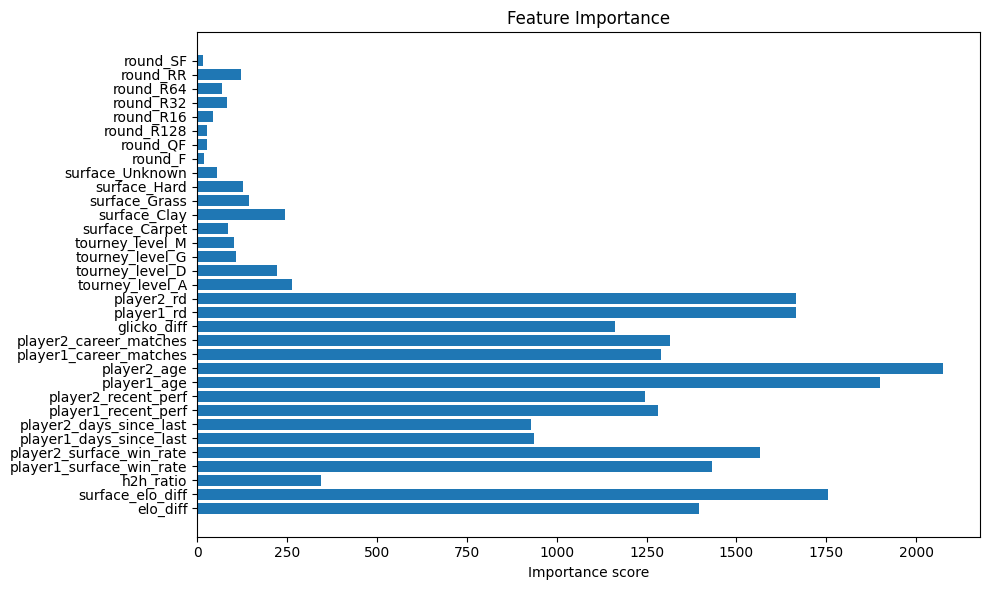

In [2]:
os.environ["JOBLIB_TEMP_FOLDER"] = "/home/francisco/tmp"
os.makedirs("/home/francisco/tmp", exist_ok=True)

# Set up logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')
logger = logging.getLogger(__name__)

def load_data(file_path='../src/tennis_matches_balanced.csv'):
    """Load the tennis match dataset."""
    logger.info(f"Loading dataset from {file_path}")
    try:
        # Attempt to load the dataset
        df = pd.read_csv(file_path)
        logger.info(f"Successfully loaded dataset with shape {df.shape}")
        return df
    except Exception as e:
        logger.error(f"Error loading dataset: {str(e)}")
        raise

def prepare_features(df):
    """Extract and prepare the required features."""
    logger.info("Extracting and preparing features")
    
    # Check if all required features exist in the dataset
    required_features = [
    'elo_diff',
    'surface_elo_diff',
    'h2h_ratio',  # h2h_recent_ratio removed: 99% the same as h2h_ratio
    'player1_surface_win_rate',
    'player2_surface_win_rate',
    'player1_days_since_last',
    'player2_days_since_last',
    'player1_recent_perf',
    'player2_recent_perf',
    'player1_age',
    'player2_age',
    'player1_career_matches',
    'player2_career_matches',
    'glicko_diff',  # Glicko-2 rating difference and each player's rating uncertainty (ratings.py)
    'player1_rd',
    'player2_rd',
    'player1_matches_last_X_days',  # matches in the last 30 days and injury break (data_extraction, ratings.rest())
    'player2_matches_last_X_days',
    'player1_injury_break',
    'player2_injury_break',
    'best_of'  # 3 or 5 sets: favourites win best-of-5 matches more often
]
    categorical_cols = ['tourney_level', 'surface', 'round']

    # Combine all features to select
    all_features = required_features + categorical_cols

    missing_features = [feat for feat in all_features if feat not in df.columns]
    if missing_features:
        logger.error(f"Missing required features: {missing_features}")
        raise ValueError(f"Dataset is missing required features: {missing_features}")

    # Select both numeric and categorical features
    features = df[all_features]

    # One-hot encode categorical columns
    features = pd.get_dummies(features, columns=categorical_cols)
    
    possible_targets = ['outcome']
    found = False
    for col in possible_targets:
        if col in df.columns:
            target = df[col]
            logger.info(f"Using '{col}' as target variable")
            found = True
            break
    
    if not found:
        logger.error("No target variable found in the dataset")
        raise ValueError("Could not identify target variable in the dataset")
    
    logger.info(f"Features shape: {features.shape}, Target shape: {target.shape}")
    return features, target

from sklearn.base import clone

def train_model(X_train, y_train, X_test, y_test, n_splits=5):
    """Train an XGBoost model with Bayesian optimization (Optuna) using TimeSeriesSplit cross-validation."""
    logger.info("Starting model training with XGBoost and Optuna Bayesian optimization (with TimeSeriesSplit CV)")

    def objective(trial):
        param = {
            'objective': 'binary:logistic',
            'tree_method': 'hist',
            'device': 'cuda',  # GPU (gpu_hist is deprecated)
            'eval_metric': 'logloss',  # early stopping on log loss (smoother than error)
            'n_estimators': 2000,          # the number of trees is chosen by early stopping on each fold
            'early_stopping_rounds': 50,
            'max_depth': trial.suggest_int('max_depth', 3, 8),
            'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.15, log=True),
            'subsample': trial.suggest_float('subsample', 0.6, 0.95),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 0.95),
            'gamma': trial.suggest_float('gamma', 0, 0.5),
            'reg_alpha': trial.suggest_float('reg_alpha', 0, 10.0),
            'reg_lambda': trial.suggest_float('reg_lambda', 0, 10.0),
            'min_child_weight': trial.suggest_int('min_child_weight', 1, 100, log=True)
        }
        model = xgb.XGBClassifier(**param)
        tscv = TimeSeriesSplit(n_splits=n_splits)
        cv_scores = []
        for train_idx, val_idx in tscv.split(X_train):
            X_tr, X_val = X_train[train_idx], X_train[val_idx]
            y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
            model.fit(
                X_tr, y_tr,
                eval_set=[(X_val, y_val)],
                verbose=False
            )
            preds = model.predict_proba(X_val)[:, 1]
            score = accuracy_score(y_val, (preds > 0.5).astype(int))
            cv_scores.append(score)
            trial.report(np.mean(cv_scores), len(cv_scores))  # lets the pruner stop clearly worse trials early
            if trial.should_prune():
                raise optuna.TrialPruned()
        return np.mean(cv_scores)

    study = optuna.create_study(direction='maximize', pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=1))
    study.optimize(objective, n_trials=50, show_progress_bar=True)

    best_params = study.best_trial.params
    logger.info(f"Best parameters found by Optuna: {best_params}")

    # Train final model with best params on full training set
    best_model = xgb.XGBClassifier(
        objective='binary:logistic',
        tree_method='hist',
        device='cuda',
        eval_metric='logloss',
        early_stopping_rounds=50,
        # number of trees chosen by early stopping: the tuned 100-300 range is too small (it settles around 600-800)
        **{**best_params, 'n_estimators': 3000}
    )
    # Early stopping on the last 10% of the training period: stopping on the test set would leak it into the model
    cut = int(len(X_train) * 0.9)
    best_model.fit(
        X_train[:cut], y_train.iloc[:cut],
        eval_set=[(X_train[cut:], y_train.iloc[cut:])],
        verbose=False
    )

    # Evaluate the model on the hold-out test set
    y_pred = best_model.predict(X_test)
    # Evaluate the model on the hold-out test set
    y_prob = best_model.predict_proba(X_test)[:, 1]

    # Threshold tuning
    best_f1 = 0
    best_thresh = 0.5
    for thresh in np.arange(0.3, 0.7, 0.01):
        preds = (y_prob >= thresh).astype(int)
        f1 = f1_score(y_test, preds)
        if f1 > best_f1:
            best_f1 = f1
            best_thresh = thresh
    logger.info(f"Best F1: {best_f1:.4f} at threshold {best_thresh:.2f}")

    # Use best threshold for final metrics
    y_pred = (y_prob >= best_thresh).astype(int)
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)

    logger.info(f"Test set Evaluation Metrics:")
    logger.info(f"Accuracy: {accuracy:.4f}")
    logger.info(f"Precision: {precision:.4f}")
    logger.info(f"Recall: {recall:.4f}")
    logger.info(f"F1 Score: {f1:.4f}")
    logger.info(f"ROC AUC: {roc_auc:.4f}")

    # Final cross-validation score on the whole training set for reporting
    tscv = TimeSeriesSplit(n_splits=n_splits)
    cv_scores = []
    for train_idx, val_idx in tscv.split(X_train):
        X_tr, X_val = X_train[train_idx], X_train[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
        cv_model = clone(best_model)  # a copy, so the returned (saved) model stays the one evaluated above
        cv_model.fit(
            X_tr, y_tr,
            eval_set=[(X_val, y_val)],
            verbose=False
        )
        preds = cv_model.predict_proba(X_val)[:, 1]
        score = accuracy_score(y_val, (preds > 0.5).astype(int))
        cv_scores.append(score)
    logger.info(f"Final CV ROC AUC scores: {cv_scores}")
    logger.info(f"Mean CV ROC AUC: {np.mean(cv_scores):.4f} ± {np.std(cv_scores):.4f}")
    print(f"Final CV ROC AUC scores: {cv_scores}")
    print(f"Mean CV ROC AUC: {np.mean(cv_scores):.4f} ± {np.std(cv_scores):.4f}")

    return best_model, best_params

def plot_feature_importance(model, feature_names):
    """Plot feature importance from the XGBoost model with feature names."""
    plt.figure(figsize=(10, 6))
    importance = model.get_booster().get_score(importance_type='weight')
    # Sort features by importance
    keys = list(importance.keys())
    values = [importance[k] for k in keys]
    # Map f0, f1, ... to real feature names
    labels = [feature_names[int(k[1:])] for k in keys]
    y_pos = np.arange(len(labels))
    plt.barh(y_pos, values, align='center')
    plt.yticks(y_pos, labels)
    plt.xlabel('Importance score')
    plt.title('Feature Importance')
    plt.tight_layout()
    plt.savefig('feature_importance.png')
    logger.info("Feature importance plot saved as 'feature_importance.png'")

def main():
    """Main function to run the training pipeline."""

    try:
        # Load data
        dataset_folder = '../training_data_set/tennis_matches_balanced.csv'
        dataset_folder = os.path.expanduser(dataset_folder)
        df = load_data(dataset_folder)
        
        df = df.sort_values('tourney_date').reset_index(drop=True)
        X, y = prepare_features(df)

        # Calculate split index for 80% train, 20% test
        split_idx = int(len(X) * 0.8)

        # Chronological split
        X_train = X.iloc[:split_idx]
        X_test = X.iloc[split_idx:]
        y_train = y.iloc[:split_idx]
        y_test = y.iloc[split_idx:]

        logger.info(f"Train set: {X_train.shape}, Test set: {X_test.shape}")

        model_path = 'accuracy_model.json'
        scaler_path = 'accuracy_scaler.joblib'

        # Check if model already exists
        if os.path.exists(model_path) and os.path.exists(scaler_path):
            logger.info(f"Model already exists at {model_path}, skipping training.")
            # Load model and scaler
            model = xgb.XGBClassifier()
            model.load_model(model_path)
            scaler = joblib.load(scaler_path)
            X_train_scaled = scaler.transform(X_train)
            X_test_scaled = scaler.transform(X_test)
        else:
            # Scale features (optional, but can help with some models)
            scaler = StandardScaler()
            X_train_scaled = scaler.fit_transform(X_train)
            X_test_scaled = scaler.transform(X_test)
            print("Train target distribution:\n", y_train.value_counts())
            print("Test target distribution:\n", y_test.value_counts())
            
            # Train model
            model, best_params = train_model(X_train_scaled, y_train, X_test_scaled, y_test)
            
            # Save model as JSON
            model.save_model(model_path)
            logger.info(f"Model saved to {model_path}")

            # Save scaler for future preprocessing
            joblib.dump(scaler, scaler_path)
            logger.info(f"Scaler saved to {scaler_path}")

            # Also save the best parameters
            with open('best_params_acc.txt', 'w') as f:
                for param, value in best_params.items():
                    f.write(f"{param}: {value}\n")
            logger.info("Best parameters saved to 'best_params_acc.txt'")

        # Plot feature importance
        plot_feature_importance(model, X.columns)
        logger.info("Feature importance plot generated.")

        print("Correlation matrix (including outcome):")
        df_check = X.copy()
        df_check['outcome'] = y
        print(df_check.corr())
        print(df_check.head(20))
        
        logger.info("Training pipeline completed successfully")
        
    except Exception as e:
        logger.error(f"Error in training pipeline: {str(e)}")
        raise

main()

**Model Training Summary**

- **Mean Accuracy:** 0.7627 ± 0.0224
- **Model saved:** `accuracy_model.json`
- **Scaler saved:** `accuracy_scaler.joblib`
- **Final CV Accuracy scores:** [0.7921, 0.7786, 0.7675, 0.7301, 0.7452]
- **Status:** Training pipeline completed successfully

2026-10-23 01:10:32,788 - INFO - Loading dataset from ../training_data_set/tennis_matches_balanced.csv


2026-10-23 01:10:34,027 - INFO - Successfully loaded dataset with shape (401366, 52)


2026-10-23 01:10:34,088 - INFO - Extracting and preparing features


2026-10-23 01:10:34,159 - INFO - Using 'outcome' as target variable


2026-10-23 01:10:34,160 - INFO - Features shape: (401366, 36), Target shape: (401366,)


...

2026-10-23 01:15:52,394 - INFO - Feature importance plot saved as 'feature_importance.png'


2026-10-23 01:15:52,395 - INFO - Feature importance plot generated.


Correlation matrix (including outcome):


2026-10-23 01:15:53,543 - INFO - Training pipeline completed successfully


                              elo_diff  surface_elo_diff     h2h_ratio  \
elo_diff                  1.000000e+00      8.380384e-01  2.993056e-01   
surface_elo_diff          8.380384e-01      1.000000e+00  2.891245e-01   
h2h_ratio                 2.993056e-01      2.891245e-01  1.000000e+00   
player1_surface_win_rate  3.456925e-01      4.253373e-01  1.482722e-01   
player2_surface_win_rate -3.456925e-01     -4.253373e-01 -1.482722e-01   
player1_days_since_last  -1.156172e-01     -8.520983e-02 -4.041072e-03   
player2_days_since_last   1.156172e-01      8.520983e-02  4.041072e-03   
player1_recent_perf       2.758924e-01      2.339878e-01  9.072207e-02   
player2_recent_perf      -2.758924e-01     -2.339878e-01 -9.072207e-02   
player1_age               7.493590e-02      1.013582e-01  2.351035e-02   
player2_age              -7.493590e-02     -1.013582e-01 -2.351035e-02   
player1_career_matches    3.417485e-01      3.513743e-01  1.642066e-01   
player2_career_matches   -3.417485e-01

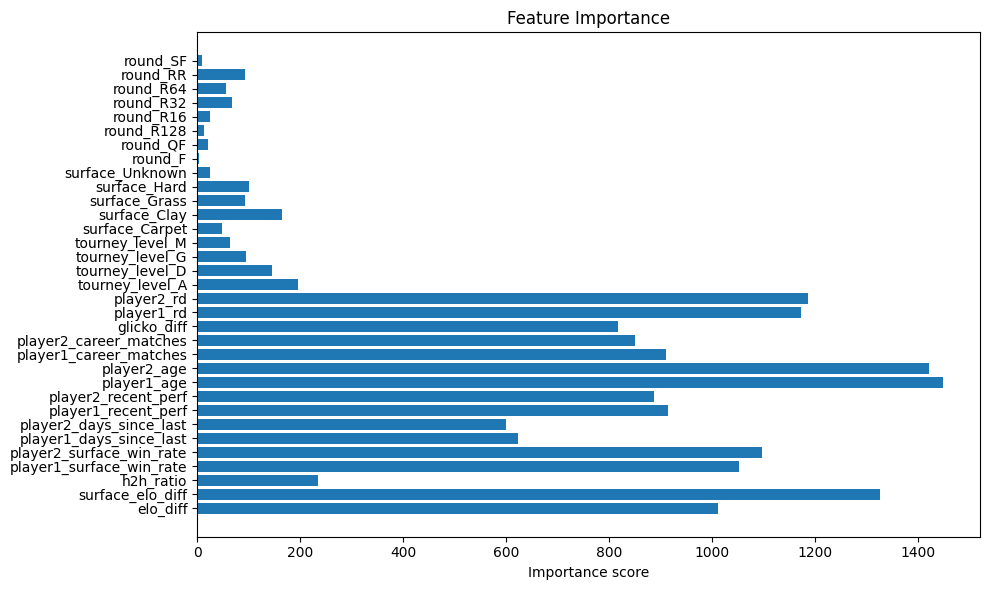

In [3]:
os.environ["JOBLIB_TEMP_FOLDER"] = "/home/francisco/tmp"
os.makedirs("/home/francisco/tmp", exist_ok=True)

# Set up logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')
logger = logging.getLogger(__name__)

def load_data(file_path='../src/tennis_matches_balanced.csv'):
    """Load the tennis match dataset."""
    logger.info(f"Loading dataset from {file_path}")
    try:
        # Attempt to load the dataset
        df = pd.read_csv(file_path)
        logger.info(f"Successfully loaded dataset with shape {df.shape}")
        return df
    except Exception as e:
        logger.error(f"Error loading dataset: {str(e)}")
        raise

def prepare_features(df):
    """Extract and prepare the required features."""
    logger.info("Extracting and preparing features")
    
    # Check if all required features exist in the dataset
    required_features = [
    'elo_diff',
    'surface_elo_diff',
    'h2h_ratio',  # h2h_recent_ratio removed: 99% the same as h2h_ratio
    'player1_surface_win_rate',
    'player2_surface_win_rate',
    'player1_days_since_last',
    'player2_days_since_last',
    'player1_recent_perf',
    'player2_recent_perf',
    'player1_age',
    'player2_age',
    'player1_career_matches',
    'player2_career_matches',
    'glicko_diff',  # Glicko-2 rating difference and each player's rating uncertainty (ratings.py)
    'player1_rd',
    'player2_rd',
    'player1_matches_last_X_days',  # matches in the last 30 days and injury break (data_extraction, ratings.rest())
    'player2_matches_last_X_days',
    'player1_injury_break',
    'player2_injury_break',
    'best_of'  # 3 or 5 sets: favourites win best-of-5 matches more often
]
    categorical_cols = ['tourney_level', 'surface', 'round']

    # Combine all features to select
    all_features = required_features + categorical_cols

    missing_features = [feat for feat in all_features if feat not in df.columns]
    if missing_features:
        logger.error(f"Missing required features: {missing_features}")
        raise ValueError(f"Dataset is missing required features: {missing_features}")

    # Select both numeric and categorical features
    features = df[all_features]

    # One-hot encode categorical columns
    features = pd.get_dummies(features, columns=categorical_cols)
    
    possible_targets = ['outcome']
    found = False
    for col in possible_targets:
        if col in df.columns:
            target = df[col]
            logger.info(f"Using '{col}' as target variable")
            found = True
            break
    
    if not found:
        logger.error("No target variable found in the dataset")
        raise ValueError("Could not identify target variable in the dataset")
    
    logger.info(f"Features shape: {features.shape}, Target shape: {target.shape}")
    return features, target

from sklearn.base import clone

def train_model(X_train, y_train, X_test, y_test, n_splits=5):
    """Train an XGBoost model with Bayesian optimization (Optuna) using TimeSeriesSplit cross-validation."""
    logger.info("Starting model training with XGBoost and Optuna Bayesian optimization (with TimeSeriesSplit CV)")

    def objective(trial):
        param = {
            'objective': 'binary:logistic',
            'tree_method': 'hist',
            'device': 'cuda',  # GPU (gpu_hist is deprecated)
            'eval_metric': 'logloss',  # early stopping on log loss (smoother than error)
            'n_estimators': 2000,          # the number of trees is chosen by early stopping on each fold
            'early_stopping_rounds': 50,
            'max_depth': trial.suggest_int('max_depth', 3, 8),
            'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.15, log=True),
            'subsample': trial.suggest_float('subsample', 0.6, 0.95),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 0.95),
            'gamma': trial.suggest_float('gamma', 0, 0.5),
            'reg_alpha': trial.suggest_float('reg_alpha', 0, 10.0),
            'reg_lambda': trial.suggest_float('reg_lambda', 0, 10.0),
            'min_child_weight': trial.suggest_int('min_child_weight', 1, 100, log=True)
        }
        model = xgb.XGBClassifier(**param)
        tscv = TimeSeriesSplit(n_splits=n_splits)
        cv_scores = []
        for train_idx, val_idx in tscv.split(X_train):
            X_tr, X_val = X_train[train_idx], X_train[val_idx]
            y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
            model.fit(
                X_tr, y_tr,
                eval_set=[(X_val, y_val)],
                verbose=False
            )
            preds = model.predict_proba(X_val)[:, 1]
            score = log_loss(y_val, preds)
            cv_scores.append(score)
            trial.report(np.mean(cv_scores), len(cv_scores))  # lets the pruner stop clearly worse trials early
            if trial.should_prune():
                raise optuna.TrialPruned()
        return np.mean(cv_scores)

    study = optuna.create_study(direction='minimize', pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=1))  # log loss: lower is better
    study.optimize(objective, n_trials=50, show_progress_bar=True)

    best_params = study.best_trial.params
    logger.info(f"Best parameters found by Optuna: {best_params}")

    # Train final model with best params on full training set
    best_model = xgb.XGBClassifier(
        objective='binary:logistic',
        tree_method='hist',
        device='cuda',
        eval_metric='logloss',
        early_stopping_rounds=50,
        # number of trees chosen by early stopping: the tuned 100-300 range is too small (it settles around 600-800)
        **{**best_params, 'n_estimators': 3000}
    )
    # Early stopping on the last 10% of the training period: stopping on the test set would leak it into the model
    cut = int(len(X_train) * 0.9)
    best_model.fit(
        X_train[:cut], y_train.iloc[:cut],
        eval_set=[(X_train[cut:], y_train.iloc[cut:])],
        verbose=False
    )

    # Evaluate the model on the hold-out test set
    y_pred = best_model.predict(X_test)
    # Evaluate the model on the hold-out test set
    y_prob = best_model.predict_proba(X_test)[:, 1]

    # Threshold tuning
    best_f1 = 0
    best_thresh = 0.5
    for thresh in np.arange(0.3, 0.7, 0.01):
        preds = (y_prob >= thresh).astype(int)
        f1 = f1_score(y_test, preds)
        if f1 > best_f1:
            best_f1 = f1
            best_thresh = thresh
    logger.info(f"Best F1: {best_f1:.4f} at threshold {best_thresh:.2f}")

    # Use best threshold for final metrics
    y_prob = best_model.predict_proba(X_test)[:, 1]
    logloss = log_loss(y_test, y_prob)
    accuracy = accuracy_score(y_test, (y_prob > 0.5).astype(int))
    precision = precision_score(y_test, (y_prob > 0.5).astype(int), zero_division=0)
    recall = recall_score(y_test, (y_prob > 0.5).astype(int))
    f1 = f1_score(y_test, (y_prob > 0.5).astype(int))
    roc_auc = roc_auc_score(y_test, y_prob)

    logger.info(f"Test set Evaluation Metrics:")
    logger.info(f"Log Loss: {logloss:.4f}")
    logger.info(f"Accuracy: {accuracy:.4f}")
    logger.info(f"Precision: {precision:.4f}")
    logger.info(f"Recall: {recall:.4f}")
    logger.info(f"F1 Score: {f1:.4f}")
    logger.info(f"ROC AUC: {roc_auc:.4f}")

    # Final cross-validation score on the whole training set for reporting
    tscv = TimeSeriesSplit(n_splits=n_splits)
    cv_scores = []
    for train_idx, val_idx in tscv.split(X_train):
        X_tr, X_val = X_train[train_idx], X_train[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
        cv_model = clone(best_model)  # a copy, so the returned (saved) model stays the one evaluated above
        cv_model.fit(
            X_tr, y_tr,
            eval_set=[(X_val, y_val)],
            verbose=False
        )
        preds = cv_model.predict_proba(X_val)[:, 1]
        score = log_loss(y_val, preds)
        cv_scores.append(score)
    logger.info(f"Final CV ROC AUC scores: {cv_scores}")
    logger.info(f"Mean CV ROC AUC: {np.mean(cv_scores):.4f} ± {np.std(cv_scores):.4f}")
    print(f"Final CV ROC AUC scores: {cv_scores}")
    print(f"Mean CV ROC AUC: {np.mean(cv_scores):.4f} ± {np.std(cv_scores):.4f}")

    return best_model, best_params

def plot_feature_importance(model, feature_names):
    """Plot feature importance from the XGBoost model with feature names."""
    plt.figure(figsize=(10, 6))
    importance = model.get_booster().get_score(importance_type='weight')
    # Sort features by importance
    keys = list(importance.keys())
    values = [importance[k] for k in keys]
    # Map f0, f1, ... to real feature names
    labels = [feature_names[int(k[1:])] for k in keys]
    y_pos = np.arange(len(labels))
    plt.barh(y_pos, values, align='center')
    plt.yticks(y_pos, labels)
    plt.xlabel('Importance score')
    plt.title('Feature Importance')
    plt.tight_layout()
    plt.savefig('feature_importance.png')
    logger.info("Feature importance plot saved as 'feature_importance.png'")

def main():
    try:
        dataset_folder = '../training_data_set/tennis_matches_balanced.csv'
        dataset_folder = os.path.expanduser(dataset_folder)
        df = load_data(dataset_folder)
        df = df.sort_values('tourney_date').reset_index(drop=True)
        X, y = prepare_features(df)
        split_idx = int(len(X) * 0.8)
        X_train = X.iloc[:split_idx]
        X_test = X.iloc[split_idx:]
        y_train = y.iloc[:split_idx]
        y_test = y.iloc[split_idx:]
        logger.info(f"Train set: {X_train.shape}, Test set: {X_test.shape}")

        model_path = 'logloss_model.json'
        scaler_path = 'scaler.joblib'

        if os.path.exists(model_path) and os.path.exists(scaler_path):
            logger.info(f"Model already exists at {model_path}, skipping training.")
            model = xgb.XGBClassifier()
            model.load_model(model_path)
            scaler = joblib.load(scaler_path)
            X_train_scaled = scaler.transform(X_train)
            X_test_scaled = scaler.transform(X_test)
        else:
            scaler = StandardScaler()
            X_train_scaled = scaler.fit_transform(X_train)
            X_test_scaled = scaler.transform(X_test)
            print("Train target distribution:\n", y_train.value_counts())
            print("Test target distribution:\n", y_test.value_counts())
            model, best_params = train_model(X_train_scaled, y_train, X_test_scaled, y_test)
            model.save_model(model_path)
            logger.info(f"Model saved to {model_path}")
            joblib.dump(scaler, scaler_path)
            logger.info(f"Scaler saved to {scaler_path}")
            with open('best_params.txt', 'w') as f:
                for param, value in best_params.items():
                    f.write(f"{param}: {value}\n")
            logger.info("Best parameters saved to 'best_params.txt'")

        plot_feature_importance(model, X.columns)
        logger.info("Feature importance plot generated.")

        print("Correlation matrix (including outcome):")
        df_check = X.copy()
        df_check['outcome'] = y
        print(df_check.corr())
        print(df_check.head(20))
        logger.info("Training pipeline completed successfully")
    except Exception as e:
        logger.error(f"Error in training pipeline: {str(e)}")
        raise

if __name__ == '__main__':  # update.py loads this cell's functions without training
    main()

## Final model for real predictions

The models above are trained on matches up to July 2012 only, so the rest can be used to test them. For predicting new matches, the log-loss model's tuned settings (and its number of trees, found by early stopping) are retrained on **all** matches. This model can't be tested anymore (no unseen matches left), which is expected.

In [4]:
df = load_data(os.path.expanduser('../training_data_set/tennis_matches_balanced.csv'))
df = df.sort_values('tourney_date').reset_index(drop=True)
X, y = prepare_features(df)

# Tuned settings and number of trees of the tested log-loss model
tested = xgb.XGBClassifier()
tested.load_model('logloss_model.json')
params = dict(line.split(': ') for line in open('best_params.txt').read().splitlines())
params = {k: int(v) if k in ('max_depth', 'min_child_weight') else float(v) for k, v in params.items()}
n_trees = tested.best_iteration + 1

final_scaler = StandardScaler().fit(X)
final_model = xgb.XGBClassifier(objective='binary:logistic', tree_method='hist', device='cuda', eval_metric='logloss',
                                n_estimators=n_trees, **params)
final_model.fit(final_scaler.transform(X), y)
final_model.save_model('final_model.json')
joblib.dump(final_scaler, 'final_scaler.joblib')
logger.info(f"Final model: {n_trees} trees, {params}, trained on {len(X)} rows up to {df['tourney_date'].max()}")


2026-10-23 01:15:53,761 - INFO - Loading dataset from ../training_data_set/tennis_matches_balanced.csv


2026-10-23 01:15:55,372 - INFO - Successfully loaded dataset with shape (401366, 52)


2026-10-23 01:15:55,446 - INFO - Extracting and preparing features


2026-10-23 01:15:55,541 - INFO - Using 'outcome' as target variable


2026-10-23 01:15:55,542 - INFO - Features shape: (401366, 36), Target shape: (401366,)


2026-10-23 01:15:59,589 - INFO - Final model: 618 trees, {'max_depth': 5, 'learning_rate': 0.025418074695943614, 'subsample': 0.6117224647661766, 'colsample_bytree': 0.6945430560961049, 'gamma': 0.44519586922553767, 'reg_alpha': 9.640036526137582, 'reg_lambda': 6.538410955319244, 'min_child_weight': 38}, trained on 401366 rows up to 20261018


**Model Training Summary**

- **Mean Log Loss:** 0.5499 ± 0.0228
- **Final Log Loss:** [0.5199, 0.5342, 0.5432, 0.5806, 0.5717]
- **Model saved:** `scaler.json`
- **Scaler saved:** `scaler.joblib`
- **Status:** Training pipeline completed successfully

In [6]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, f1_score
import xgboost as xgb

# --- Load Data ---
dataset_folder = '../training_data_set/tennis_matches_balanced.csv'
dataset_folder = os.path.expanduser(dataset_folder)
df = load_data(dataset_folder)
df = df.sort_values('tourney_date').reset_index(drop=True)

features = [
    'elo_diff', 'surface_elo_diff', 'h2h_ratio',
    'player1_surface_win_rate', 'player2_surface_win_rate',
    'player1_days_since_last', 'player2_days_since_last',
    'player1_recent_perf', 'player2_recent_perf',
    'player1_age', 'player2_age', 'player1_career_matches', 'player2_career_matches',
    'tourney_level', 'surface', 'round'
]
target = 'outcome'

# --- One-hot encode categoricals ---
X_base = df[features]
X_base = pd.get_dummies(X_base, columns=['tourney_level', 'surface', 'round'])
y = df[target]

# --- Chronological split (time-dependent, no shuffling) ---
split_idx = int(len(X_base) * 0.8)
X_train_base = X_base.iloc[:split_idx]
X_test_base = X_base.iloc[split_idx:]
y_train = y.iloc[:split_idx]
y_test = y.iloc[split_idx:]

def run_experiment(X_train, X_test, y_train, y_test, label):
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    model = xgb.XGBClassifier(eval_metric='logloss', device='cuda')
    model.fit(X_train_scaled, y_train)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    roc_auc = roc_auc_score(y_test, y_prob)
    f1 = f1_score(y_test, (y_prob > 0.5).astype(int))
    print(f"{label} ROC AUC: {roc_auc:.4f}, F1: {f1:.4f}, Log loss: {log_loss(y_test, y_prob):.4f}, "
          f"Accuracy: {accuracy_score(y_test, (y_prob > 0.5).astype(int)):.4f}")

# --- Baseline ---
run_experiment(X_train_base, X_test_base, y_train, y_test, "Baseline")

# --- Interaction: elo_diff * surface_elo_diff ---
X_inter = X_base.copy()
X_inter['elo_surface_interaction'] = df['elo_diff'] * df['surface_elo_diff']
X_train_inter = X_inter.iloc[:split_idx]
X_test_inter = X_inter.iloc[split_idx:]
run_experiment(X_train_inter, X_test_inter, y_train, y_test, "elo_diff * surface_elo_diff")

# --- Interaction: h2h_ratio * player1_recent_perf ---
X_inter2 = X_base.copy()
X_inter2['h2h_perf_interaction'] = df['h2h_ratio'] * df['player1_recent_perf']
X_train_inter2 = X_inter2.iloc[:split_idx]
X_test_inter2 = X_inter2.iloc[split_idx:]
run_experiment(X_train_inter2, X_test_inter2, y_train, y_test, "h2h_ratio * player1_recent_perf")

# --- Difference: player1_surface_win_rate - player2_surface_win_rate ---
X_diff = X_base.copy()
X_diff['surface_win_diff'] = df['player1_surface_win_rate'] - df['player2_surface_win_rate']
X_train_diff = X_diff.iloc[:split_idx]
X_test_diff = X_diff.iloc[split_idx:]
run_experiment(X_train_diff, X_test_diff, y_train, y_test, "player1_surface_win_rate - player2_surface_win_rate")

# --- Polynomial: (elo_diff)^2 ---
X_poly = X_base.copy()
X_poly['elo_diff_squared'] = df['elo_diff'] ** 2
X_train_poly = X_poly.iloc[:split_idx]
X_test_poly = X_poly.iloc[split_idx:]
run_experiment(X_train_poly, X_test_poly, y_train, y_test, "elo_diff squared")

2026-10-22 14:31:15,987 - INFO - Loading dataset from /home/francisco/Desktop/tenis_ai/tenis-prediction-model/training_data_set/tennis_matches_balanced.csv


2026-10-22 14:31:17,105 - INFO - Successfully loaded dataset with shape (401366, 49)


Baseline ROC AUC: 0.7367, F1: 0.6698, Log loss: 0.6025, Accuracy: 0.6699


elo_diff * surface_elo_diff ROC AUC: 0.7378, F1: 0.6687, Log loss: 0.6011, Accuracy: 0.6696


h2h_ratio * player1_recent_perf ROC AUC: 0.7372, F1: 0.6692, Log loss: 0.6020, Accuracy: 0.6693


player1_surface_win_rate - player2_surface_win_rate ROC AUC: 0.7373, F1: 0.6702, Log loss: 0.6020, Accuracy: 0.6696


elo_diff squared ROC AUC: 0.7378, F1: 0.6703, Log loss: 0.6013, Accuracy: 0.6704


## Elo momentum vs consecutive wins

Both describe the last 5 matches: consecutive wins only counts the current win streak, Elo momentum is how much the player's Elo moved over those matches (beating strong players counts more, losing to weak ones costs more). Each is added on top of the same baseline as above.

In [7]:
streak = ['player1_consec_wins', 'player2_consec_wins']
momentum = ['player1_elo_momentum', 'player2_elo_momentum']

for label, cols in [('+ consec_wins', streak), ('+ elo_momentum', momentum), ('+ both', streak + momentum)]:
    X = X_base.join(df[cols])
    run_experiment(X.iloc[:split_idx], X.iloc[split_idx:], y_train, y_test, label)


+ consec_wins ROC AUC: 0.7376, F1: 0.6707, Log loss: 0.6017, Accuracy: 0.6701


+ elo_momentum ROC AUC: 0.7373, F1: 0.6703, Log loss: 0.6017, Accuracy: 0.6694


+ both ROC AUC: 0.7381, F1: 0.6693, Log loss: 0.6008, Accuracy: 0.6693


## Serve/return form

Each player's 1st serve points won %, break points converted % and return games won % over their last 10 matches (stats from Sackmann, 1991 to May 2026), added one at a time and all together on top of the same baseline.

In [8]:
serve_return = {
    'first_serve_won': ['player1_first_serve_won', 'player2_first_serve_won'],
    'bp_converted': ['player1_bp_converted', 'player2_bp_converted'],
    'return_games_won': ['player1_return_games_won', 'player2_return_games_won'],
}
for label, cols in [(f'+ {name}', cols) for name, cols in serve_return.items()] + [('+ all three', sum(serve_return.values(), []))]:
    X = X_base.join(df[cols])
    run_experiment(X.iloc[:split_idx], X.iloc[split_idx:], y_train, y_test, label)


+ first_serve_won ROC AUC: 0.7364, F1: 0.6693, Log loss: 0.6015, Accuracy: 0.6693


+ bp_converted ROC AUC: 0.7352, F1: 0.6690, Log loss: 0.6028, Accuracy: 0.6687


+ return_games_won ROC AUC: 0.7355, F1: 0.6675, Log loss: 0.6024, Accuracy: 0.6688


+ all three ROC AUC: 0.7348, F1: 0.6674, Log loss: 0.6032, Accuracy: 0.6675
